Shahlo Solieva 

Created 07102026 | Modified 07292026

RMSD of paratope to the crystal/cryo-EM structure. Paratope defined by antibody residue within 10A of antigen (protein or glycan). See CSV files from the distance analysis for a list of every residue's distance from antigen protein or glycan atoms.

In [1]:
import numpy as np
import mdtraj as md
import pickle
import matplotlib.pyplot as plt

# RMSD

In [2]:
def get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, target_HC_resis, ref_LC_resis, target_LC_resis, ref_chains=[0,1], target_chains=[0,1]):
    # import ref info:
    #print(ref_chains)
    ref_pdb = md.load(ref_pdb_path)
    #print(ref_pdb)
    ref_fr_indices = np.load(ref_FR_inds_path)

    ref_paratope_indices = np.concatenate([ref_pdb.topology.select(f'chainid {ref_chains[0]} and residue {ref_HC_resis} and name CA'),
                                           ref_pdb.topology.select(f'chainid {ref_chains[1]} and residue {ref_LC_resis} and name CA')])
    #print(len(ref_paratope_indices), ref_paratope_indices[-10:])

    # import target info:
    sys_name=target_sys_name
    cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data/apo/{sys_name}/"
    target_pdb = md.load(f'{cluster_dir_path}prot_masses.pdb')
    # step 2: import cluster centers:
    file=f"{cluster_dir_path}cluster-centers.pickle"
    with open(file, 'rb') as file:
        centers=pickle.load(file) # load in cluster centers.
    target_fr_indices = np.load(f'../data/{sys_name}-FR-indices.npy')
    #target_paratope_indices=np.load(f'../data/{sys_name}-paratope-indices.npy')
    target_paratope_indices = np.concatenate([target_pdb.topology.select(f'chainid {target_chains[0]} and residue {target_HC_resis} and name CA'),
                                              target_pdb.topology.select(f'chainid {target_chains[1]} and residue {target_LC_resis} and name CA')])
    #print(len(target_paratope_indices), target_paratope_indices[-10:])

    resis_included=[]
    for i in range(len(target_paratope_indices)):
        resis_included.append(target_pdb.topology.atom(target_paratope_indices[i]).residue)
    print(resis_included)
    eq_probs = np.load(f'{cluster_dir_path}eq_probs_msm_100.npy')

    # sanity check:
    if len(target_fr_indices) != len(ref_fr_indices):
        print('ERROR len(target_fr_indices) != len(ref_fr_indices)')
    if len(target_paratope_indices) != len(ref_paratope_indices):
        print('ERROR len(target_paratope_indices) != len(ref_paratope_indices)')
        print(len(target_paratope_indices), len(ref_paratope_indices))
    if len(eq_probs) != len(centers):
        print('ERROR len(eq_probs) != len(centers)')

    # RMSD, custom fit 
    rmsd_values = []
    for center_ind in range(len(centers)):
        centers[center_ind].superpose(ref_pdb, atom_indices=target_fr_indices, ref_atom_indices=ref_fr_indices)
        ref_xyz = ref_pdb.xyz[:, ref_paratope_indices, :]
        target_xyz = centers[center_ind].xyz[0, target_paratope_indices, :]
        rmsd_no_fit = np.sqrt(np.mean(np.sum((ref_xyz - target_xyz)**2, axis=2), axis=1))
        rmsd_values.append(rmsd_no_fit[0]*10) # convert nm to Angstroms
    return rmsd_values, eq_probs

In [3]:
# colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']

# 3F8

[TYR32, ALA53, GLY54, SER56, ASN58, ARG98, HIS101, GLY103, TYR104, TYR92]
[TYR32, ALA53, GLY54, SER56, ASN58, ARG98, HIS101, GLY103, TYR104, TYR92]
[TYR32, ALA53, GLY54, ILE56, ASN58, ARG98, HIS101, GLY103, TYR104, TYR92]
5.503208041191101


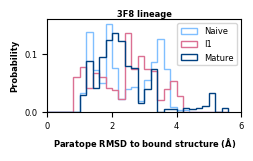

In [10]:
lineage = 'Ab3F8'

ref_LC_resis   = '92'
# target_LC_resis= ref_LC_resis

ref_HC_resis =   '32 53 54 56 58 98 101 103 104'
# same HC and LC for both naive and mature, no insertions/deletions.  


ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/3F8-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/3vfg_mature_3f8.pdb'

target_sys_name = 'Ab3F8_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab3F8_I56S_VC'
I_rmsd_values, I_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab3F8_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])
print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I_rmsd_values])))

plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,5.8,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I_rmsd_values,      bins=bins, weights=I_eq_probs,     edgecolor='palevioletred',       label='I1', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('3F8 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# PGT121

/home/ssolieva/miniconda/envs/pyemma/lib/python3.11/site-packages/mdtraj/formats/pdb/pdbfile.py:200: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn('Unlikely unit cell vectors detected in PDB file likely '


[GLN99, GLN100, GLY101, LYS102, ARG103, ILE104, TYR105, GLY106, VAL107, VAL108, SER109, PHE110, GLY111, ASP112, TYR113, TYR114, TYR115, TYR116, TYR118, ASN25, ASN26, ILE27, GLY28, SER29, LYS30, SER31, VAL32, HIS33, VAL47, TYR48, ASP49, ASP50, SER51, ASP52, ARG53, GLY63, SER64, ASN65, SER66, GLY67, ALA70, VAL89, TRP90, ASP91, SER92, SER93, SER94, ASP95, HIS96, PRO97, TRP98]
[GLN99, GLN100, GLY101, LYS102, ARG103, ILE104, TYR105, GLY106, MET107, VAL108, SER109, PHE110, GLY111, GLU112, PHE113, PHE114, TYR115, TYR116, TYR118, ARG25, SER26, LEU27, GLY28, SER29, ARG30, ALA31, VAL32, GLN33, ILE47, TYR48, ASN49, ASN50, GLN51, ASP52, ARG53, GLY63, SER64, PRO65, ASP66, SER67, ALA73, MET92, TRP93, ASP94, SER95, ARG96, SER97, ALA98, ILE99, ASN100, TRP101]
[ARG99, ARG100, GLY101, GLN102, ARG103, ILE104, TYR105, GLY106, VAL107, VAL108, SER109, PHE110, GLY111, GLU112, PHE113, PHE114, TYR115, TYR116, TYR118, ARG25, SER26, LEU27, GLY28, SER29, ARG30, ALA31, VAL32, GLN33, ILE47, TYR48, ASN49, ASN50, GLN

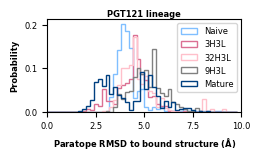

In [5]:
lineage = 'PGT121'

ref_HC_resis = '99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 118'
ref_LC_resis = '18 19 20 21 22 23 24 25 26 40 41 42 43 44 45 46 56 57 58 59 60 66 85 86 87 88 89 90 91 92 93 94'
naive_LC_resis='25 26 27 28 29 30 31 32 33 47 48 49 50 51 52 53 63 64 65 66 67 70 89 90 91 92 93 94 95 96 97 98'
I_LC_resis    ='25 26 27 28 29 30 31 32 33 47 48 49 50 51 52 53 63 64 65 66 67 73 92 93 94 95 96 97 98 99 100 101'


ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/PGT121-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/PGT121_mature_7uoj.pdb'

target_sys_name = 'PGT121_naive_lambda_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, naive_LC_resis, ref_chains=[1,0])

target_sys_name = 'PGT121_3H3L_VC'
I1_rmsd_values, I1_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, I_LC_resis, ref_chains=[1,0])

target_sys_name = 'PGT121_32H3L_VC'
I2_rmsd_values, I2_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, I_LC_resis, ref_chains=[1,0])

target_sys_name = 'PGT121_9H3L_VC'
I3_rmsd_values, I3_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, I_LC_resis, ref_chains=[1,0])

target_sys_name = 'PGT121_mature_lambda_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])


print(np.max(np.concatenate([naive_rmsd_values,I1_rmsd_values, I2_rmsd_values, I3_rmsd_values, mature_rmsd_values])))
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,10,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I1_rmsd_values,  bins=bins,weights=I1_eq_probs,        edgecolor='palevioletred', label='3H3L', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='32H3L', histtype='step')
plt.hist(I3_rmsd_values,  bins=bins,weights=I3_eq_probs,        edgecolor='gray', label='9H3L', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('PGT121 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,10)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# 1-18

/home/ssolieva/miniconda/envs/pyemma/lib/python3.11/site-packages/mdtraj/formats/pdb/pdbfile.py:200: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn('Unlikely unit cell vectors detected in PDB file likely '


[VAL2, GLN3, LEU4, VAL5, GLN6, SER7, GLY8, ALA9, LYS12, SER17, VAL18, LYS19, VAL20, SER21, LYS23, ALA24, SER25, GLY26, THR28, PHE29, THR30, SER31, TYR32, TYR33, HIS35, TRP47, GLY49, ILE50, ILE51, ASN52, PRO53, SER54, GLY55, GLY56, SER57, THR58, SER59, TYR60, ALA61, GLN62, LYS63, PHE64, GLN65, GLY66, VAL68, THR69, MET70, THR71, ARG72, ASP73, THR74, SER75, THR76, SER77, THR78, VAL79, TYR80, MET81, GLU82, SER84, ARG98, ASP99, PRO100, PHE101, GLY102, GLU103, ARG104, ALA105, PRO106, TYR107, TYR108, TYR109, TYR110, GLY117, GLY118, THR119, ALA120, GLU1, ILE2, VAL3, CYS23, ARG24, ALA25, SER26, GLN27, SER28, VAL29, SER30, SER31, SER32, TYR33, LEU34, GLY42, GLY51, ALA52, SER53, THR57, GLY65, SER66, GLY67, SER68, GLY69, THR70, ASP71, PHE72, GLN91, TYR92, GLY93, SER94, SER95, PRO96, LEU97]
[VAL2, GLN3, LEU4, VAL5, GLN6, SER7, GLY8, ALA9, LYS12, SER17, VAL18, LYS19, VAL20, SER21, ARG23, ALA24, ASP25, ASP26, THR34, PHE35, THR36, LYS37, TYR38, TRP39, HIS41, TRP53, GLY55, VAL56, ILE57, SER58, PRO59, H

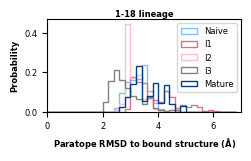

In [6]:
lineage = '1-18'

ref_LC_resis   = '1 2 3 23 24 25 26 27 28 29 30 31 32 33 34 42 51 52 53 57 65 66 67 68 69 70 71 72 91 92 93 94 95 96 97'
# target_LC_resis= ref_LC_resis

ref_HC_resis =   '2 3 4 5 6 7 8 9 12 17 18 19 20 21 23 24 25 26 34 35 36 37 38 39 41 53 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 90 104 105 106 107 108 109 110 111 112 113 114 115 116 123 124 125 126'
#'2 3 4 5 6 7 8 11 16 17 18 19 20 22 23 24 25 26 34 35 36 37 38 40 52 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 89 103 104 105 106 107 108 109 110 111 112 113 114 115 122 123 124 125'
# same HC and LC for both naive and mature, no insertions/deletions.  
# removed: 1, 27 28 29 30 31 32 33. 34 mature = 28 naive! (insertion in mature)
naive_HC_resis = '2 3 4 5 6 7 8 9 12 17 18 19 20 21 23 24 25 26 28 29 30 31 32 33 35 47 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 84 98 99 100 101 102 103 104 105 106 107 108 109 110 117 118 119 120'
# '2 3 4 5 6 7 8 11 16 17 18 19 20 22 23 24 25 26 28 29 30 31 32 34 46 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 83 97 98 99 100 101 102 103 104 105 106 107 108 109 116 117 118 119'

ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/118-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/118_mature_6udj.pdb'

target_sys_name = 'Ab118_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab118_I_VC'
I1_rmsd_values, I1_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab118_IAb2748_VC'
I2_rmsd_values, I2_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab118_IAb0923_VC'
I3_rmsd_values, I3_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])

target_sys_name = 'Ab118_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains=[1,0])


print(np.max(np.concatenate([naive_rmsd_values,I1_rmsd_values, I2_rmsd_values, I3_rmsd_values, mature_rmsd_values])))
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,7,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I1_rmsd_values,  bins=bins,weights=I1_eq_probs,        edgecolor='palevioletred', label='I1', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='I2', histtype='step')
plt.hist(I3_rmsd_values,  bins=bins,weights=I3_eq_probs,        edgecolor='gray', label='I3', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('1-18 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# EPTC112

/home/ssolieva/miniconda/envs/pyemma/lib/python3.11/site-packages/mdtraj/formats/pdb/pdbfile.py:200: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn('Unlikely unit cell vectors detected in PDB file likely '


[VAL2, GLN3, SER19, LEU20, THR21, VAL24, SER25, GLY26, GLY27, SER28, VAL29, SER30, SER31, TYR32, TYR33, TRP34, TYR52, TYR53, SER54, GLY55, SER56, THR68, ILE69, SER70, VAL71, ASP72, THR73, SER74, LYS75, ASN76, GLN77, PHE78, SER79, LEU80, LYS81, ARG97, GLY98, TYR99, SER100, SER101, GLY102, TRP103, TYR104, ALA105, GLU106, HIS110, TYR32, TYR34, ASN97]
[VAL2, GLN3, THR19, LEU20, THR21, VAL24, PHE25, ASN26, SER27, ARG28, VAL29, SER30, GLY31, TYR32, TYR33, TYR34, HIS52, PHE53, SER54, LEU55, ARG56, THR68, THR69, SER70, ILE71, ASP72, THR73, GLU74, ARG75, TYR76, GLN77, VAL78, PHE79, LEU80, ASN81, ARG97, GLY98, ASP99, ALA100, SER101, GLY102, TRP103, ARG104, ALA105, ASP106, HIS110, SER32, TYR34, HIS97]
3.232952654361725


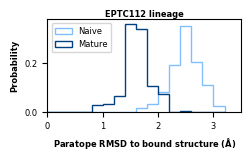

In [17]:
lineage = 'EPTC112'

ref_LC_resis   = '32 34 97'
# target_LC_resis= ref_LC_resis

ref_HC_resis =   '2 3 19 20 21 24 25 26 27 28 29 30 31 32 33 34 52 53 54 55 56 68 69 70 71 72 73 74 75 76 77 78 79 80 81 97 98 99 100 101 102 103 104 105 106 110'
# same HC and LC for both naive and mature, no insertions/deletions.  


ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/EPTC112-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/EPTC112_mature_8c8t.pdb'

target_sys_name = 'EPTC112_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'EPTC112_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis)
print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values])))

plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,3.4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('EPTC112 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,3.5)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CAP256

In [4]:
lineage='CAP256'
ref_LC_resis   = '33 47 50 51 53 54 55 56 57'
# target_LC_resis= ref_LC_resis

ref_HC_resis =   '2 23 24 25 26 27 28 29 30 31 73 76 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 117 118 119 120 121 122 123 124 125 127 128 129 131 136'
naive_HC_resis = '2 23 24 25 26 27 28 29 30 31 73 76 97 98 99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 117 118 119 120 121 122 123 124 125 126 127 128 130 135'
# removed: 1

ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/CAP256-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/CAP256_mature_6vtt.pdb'

target_sys_name = 'CAP256_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CAP256_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CAP256_I01_VC'
I01_rmsd_values, I01_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name,      ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CAP256_I03_VC'
I03_rmsd_values, I03_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name,         ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CAP256_I04_VC'
I04_rmsd_values, I04_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name,         ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CAP256_I07_VC'
I07_rmsd_values, I07_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name,         ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis, target_chains=[1,0])

target_sys_name = 'CAP256_I10_VC'
I10_rmsd_values, I10_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name,         ref_HC_resis, naive_HC_resis, ref_LC_resis, ref_LC_resis, target_chains=[1,0])


/home/ssolieva/miniconda/envs/pyemma/lib/python3.11/site-packages/mdtraj/formats/pdb/pdbfile.py:200: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn('Unlikely unit cell vectors detected in PDB file likely '


[VAL2, ALA23, ALA24, SER25, GLY26, PHE27, THR28, PHE29, SER30, SER31, ASP73, LYS76, ALA97, LYS98, ASP99, LEU100, GLY101, GLU102, SER103, GLU104, ASN105, GLU106, GLU107, TRP108, ALA109, THR110, ASP111, TYR112, TYR113, ASP114, ILE117, GLY118, TYR119, PRO120, GLY121, GLN122, ASP123, PRO124, ARG125, GLY126, VAL127, VAL128, ALA130, GLY135, TYR33, LEU47, TYR50, GLU51, ASN53, LYS54, ARG55, PRO56, SER57]
[VAL2, ALA23, ALA24, SER25, GLN26, PHE27, ARG28, PHE29, ASP30, GLY31, ASP73, LYS76, ALA97, LYS98, ASP99, LEU100, ARG101, GLU102, ASP103, GLU104, CYS105, GLU106, GLU107, TRP108, TRP109, SER110, ASP111, TYR112, TYR113, ASP114, LYS117, GLN118, LEU119, PRO120, CYS121, ALA122, LYS123, SER124, ARG125, GLY127, LEU128, VAL129, ILE131, GLY136, PHE33, LEU47, TYR50, GLU51, ASP53, LYS54, ARG55, PRO56, SER57]
[VAL2, THR23, ALA24, SER25, GLY26, PHE27, THR28, PHE29, SER30, ASN31, ASP73, LYS76, ALA97, LYS98, ASP99, VAL100, GLY101, ASP102, TYR103, LYS104, SER105, ASP106, GLU107, TRP108, GLY109, THR110, GLU111,

22.388441562652588


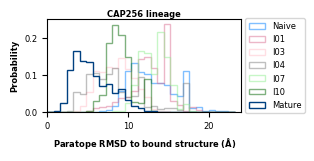

In [5]:
print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I01_rmsd_values,I03_rmsd_values,I04_rmsd_values, I07_rmsd_values, I10_rmsd_values])))


plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,24,0.8)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I01_rmsd_values,    bins=bins, weights=I01_eq_probs,   alpha=0.5, edgecolor='palevioletred', label='I01', histtype='step')
plt.hist(I03_rmsd_values,    bins=bins, weights=I03_eq_probs,   alpha=0.5, edgecolor='pink', label='I03', histtype='step')
plt.hist(I04_rmsd_values,    bins=bins, weights=I04_eq_probs,   alpha=0.5, edgecolor='gray', label='I04', histtype='step')
plt.hist(I07_rmsd_values,    bins=bins, weights=I07_eq_probs,   alpha=0.5, edgecolor='lightgreen', label='I07', histtype='step')
plt.hist(I10_rmsd_values,    bins=bins, weights=I10_eq_probs,   alpha=0.5, edgecolor='darkgreen', label='I10', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CAP256 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6, loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlim(0,24)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH103

/home/ssolieva/miniconda/envs/pyemma/lib/python3.11/site-packages/mdtraj/formats/pdb/pdbfile.py:200: UserWarning: Unlikely unit cell vectors detected in PDB file likely resulting from a dummy CRYST1 record. Discarding unit cell vectors.
  warnings.warn('Unlikely unit cell vectors detected in PDB file likely '


[GLN5, SER7, GLY8, PRO9, THR17, THR23, VAL24, SER25, GLY26, GLY27, SER28, ILE29, SER30, SER31, TYR32, TYR33, TRP34, TRP47, TYR50, ILE51, TYR52, TYR53, SER54, GLY55, SER56, THR57, ASN58, TYR59, ASN60, PRO61, SER62, LEU63, LYS64, SER65, ARG66, VAL67, THR68, ILE69, SER70, VAL71, ASP72, THR73, SER74, LYS75, ASN76, GLN77, PHE78, SER79, LYS81, LEU82, SER83, SER84, LEU98, PRO99, ARG100, GLY101, GLN102, LEU103, VAL104, ASN105, ALA106, TYR107, ASP109, TYR35, GLN36, ASP50, SER51, LYS52, ARG53, PRO54, SER55, GLY56, SER66, GLY67, ASN68, THR69, ALA70, LEU72, THR73, ILE74, SER92, PHE93, SER94, THR95, PHE96, VAL97, PHE98, GLY99, THR100]
[GLN5, SER7, GLY8, PRO9, THR17, THR23, VAL24, SER25, GLY26, GLY27, SER28, MET29, GLY30, GLY31, THR32, TYR33, TRP34, TRP47, TYR50, ILE51, PHE52, HIS53, THR54, GLY55, GLU56, THR57, ASN58, TYR59, SER60, PRO61, SER62, LEU63, LYS64, GLY65, ARG66, VAL67, SER68, ILE69, SER70, VAL71, ASP72, THR73, SER74, GLU75, ASP76, GLN77, PHE78, SER79, ARG81, LEU82, ARG83, SER84, LEU98, PR

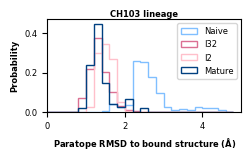

In [10]:
lineage='CH103'
ref_LC_resis   = '32 33 47 48 49 50 51 52 53 63 64 65 66 67 69 70 71 89 90 91 92 93 94 95 96 97'
target_LC_resis= '35 36 50 51 52 53 54 55 56 66 67 68 69 70 72 73 74 92 93 94 95 96 97 98 99 100'
# removed 2 26 27 29 because of naive-mature alignment!! 

ref_HC_resis = '5 7 8 9 17 23 24 25 26 27 28 29 30 31 32 33 34 47 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 81 82 83 84 98 99 100 101 102 103 104 105 106 107 109'
# same HC numbering for naive and mature.

ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/CH103-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/CH103_mature_9d7o.pdb'

ref_chains = [1,0] # HC, LC
target_sys_name = 'CH103_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, target_LC_resis, ref_chains)

target_sys_name = 'CH103_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis, ref_chains)

target_sys_name = 'CH103_I32_VC'
I32_rmsd_values, I32_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, target_LC_resis, ref_chains)

target_sys_name = 'CH103_I2_VC'
I2_rmsd_values, I2_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, target_LC_resis, ref_chains)

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I32_rmsd_values,I2_rmsd_values])))

plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,5,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I32_rmsd_values,  bins=bins,weights=I32_eq_probs,        edgecolor='palevioletred', label='I32', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH103 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,5)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# CH65

[TYR27, THR28, PHE29, THR30, GLY31, TYR32, TYR33, TRP47, TRP50, ILE51, ASN52, PRO53, ASN54, SER55, GLY56, GLY57, THR58, ASN59, TYR60, ALA61, GLN62, GLN65, ARG72, ARG98, GLY99, GLY100, GLU102, PRO103, ARG104, SER105, VAL106, ASP107, TYR108, TYR109, TYR110, TYR111, GLY112, ASN25, ASN26, ILE27, GLY28, SER29, LYS30, SER31, GLY67, ASN68, TRP90, ASP91, SER92, SER93, SER94, ASP95, HIS96]
[TYR27, THR28, PHE29, THR30, ASP31, TYR32, HIS33, TRP47, TRP50, ILE51, HIS52, PRO53, ASN54, SER55, GLY56, ASP57, THR58, ASN59, TYR60, ALA61, GLN62, GLN65, ARG72, ARG98, GLY99, GLY100, GLU102, PRO103, ARG104, SER105, VAL106, ASP107, TYR108, TYR109, TYR110, TYR111, GLY112, ASN25, ASP26, ILE27, GLY28, ARG29, LYS30, SER31, GLY67, ASN68, TRP90, ASP91, SER92, SER93, SER94, ASP95, HIS96]
[TYR27, THR28, PHE29, THR30, ASP31, TYR32, TYR33, TRP47, TRP50, ILE51, HIS52, PRO53, ASN54, SER55, GLY56, GLY57, THR58, ASN59, TYR60, ALA61, GLN62, GLN65, ARG72, ARG98, GLY99, GLY100, GLU102, PRO103, ARG104, SER105, VAL106, ASP107, 

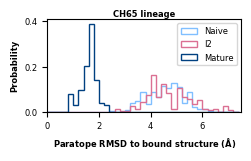

In [11]:
lineage = 'CH65'

ref_LC_resis   = '25 26 27 28 29 30 31 67 68 90 91 92 93 94 95 96'
target_LC_resis= ref_LC_resis

ref_HC_resis = '27 28 29 30 31 32 33 47 50 51 52 53 54 55 56 57 58 59 60 61 62 65 72 98 99 100 102 103 104 105 106 107 108 109 110 111 112'
target_HC_resis = ref_HC_resis

ref_FR_inds_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/CH65-ref-FR-indices.npy'
ref_pdb_path= '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/ref_structures/CH65_mature_5ugy.pdb'

target_sys_name = 'CH65_naive_VC'
naive_rmsd_values, naive_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, target_LC_resis)

target_sys_name = 'CH65_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, ref_LC_resis)

target_sys_name = 'CH65_I2_VC'
I2_rmsd_values, I2_eq_probs = get_rmsd(ref_FR_inds_path, ref_pdb_path, target_sys_name, ref_HC_resis, ref_HC_resis, ref_LC_resis, target_LC_resis)


print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I2_rmsd_values])))

plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,7.5,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='palevioletred',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Paratope RMSD to bound structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold')
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH65 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7.5)
plt.savefig(f"../figures/paratope_RMSD_to_bound_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()
